# Simulation of DCBC evaluation using gradient data 
This notebook demonstrates that the DCBC is unbiased for random gradient data. 


In [18]:
import DCBC.examples.simulation as es 
import numpy as np
import matplotlib.pyplot as plt
import colour as co

In [30]:
w=60
h=40
X,Y,D= es.make_2d_grid(height=h,width=w)
F=es.make_gaussian_field(X,Y,D,3,4)

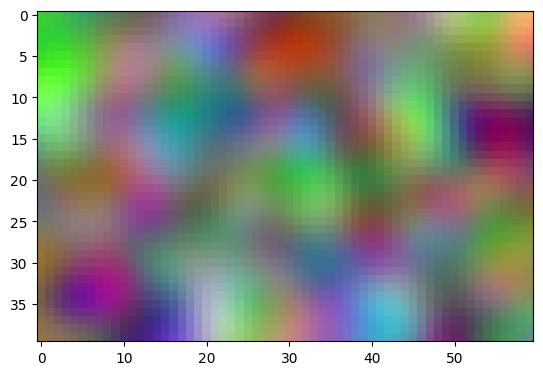

In [ ]:
img = F.reshape(3, h, w).transpose(1, 2, 0)
img = (img - img.min()) / (img.max() - img.min())  # scale to [0, 1]
plt.imshow(img)

(-0.5, 59.5, 39.5, -0.5)

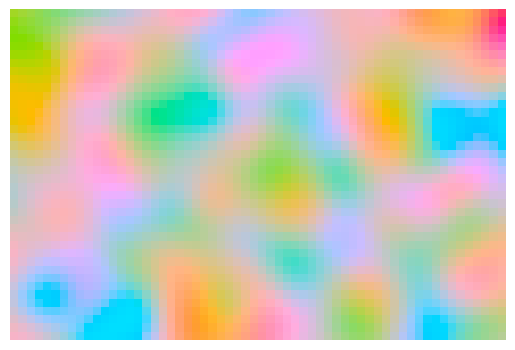

In [33]:
L = 80  # lightness (0-100)
scale = 30  # a*/b* units per standard deviation of the field
lab = np.stack([np.full(h*w, L), scale*F[0], scale*F[1]], axis=-1)
xyz = co.Lab_to_XYZ(lab, illuminant=co.CCS_ILLUMINANTS['CIE 1931 2 Degree Standard Observer']['D65'])
rgb = np.clip(co.XYZ_to_sRGB(xyz), 0, 1)   # out-of-gamut colours are clipped
plt.imshow(rgb.reshape(h, w, 3))
plt.axis('off')

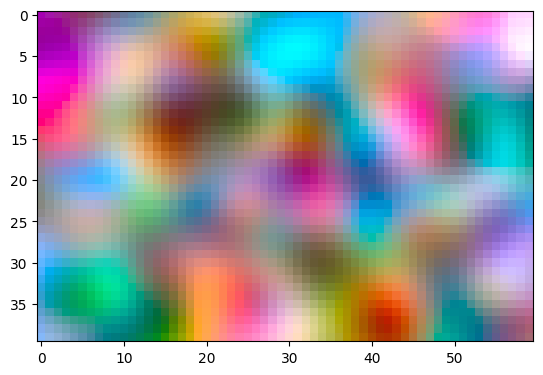

In [34]:
L0 = 60                    # mean lightness
sL, sab = 15, 30           # L* / a*,b* units per standard deviation of the field
lab = np.stack([np.clip(L0 + sL*F[0], 0, 100), sab*F[1], sab*F[2]], axis=-1)
xyz = co.Lab_to_XYZ(lab, illuminant=co.CCS_ILLUMINANTS['CIE 1931 2 Degree Standard Observer']['D65'])
rgb = np.clip(co.XYZ_to_sRGB(xyz), 0, 1)   # out-of-gamut colours are clipped
plt.imshow(rgb.reshape(h, w, 3))

In [36]:
import DCBC as dcbc 

In [ ]:
dcbc 